# Modeling baselines — predicting bad mood in unseen people

**Task.** Binary classification: will a participant report a bad mood (SAD, TENSE/ANXIOUS or TIRED = 1) vs. a neutral/good mood (0) at a given mood report?

**Evaluation strategy.**
- Only the **training file** is used here. The test file stays untouched until the final model is chosen.
- `StratifiedGroupKFold` (5 folds, grouped by participant `id`): every validation fold contains only people the model never saw, which matches the goal of predicting mood in previously unseen individuals.
- The same folds are reused for every model (`T.fixed_folds`) so comparisons are fair.
- All preprocessing (median imputation + missing-indicators, scaling) lives inside sklearn `Pipeline`s, so it is refit within each fold.

**KPIs.** Primary: **ROC-AUC** (threshold-free, robust to the ~37% base rate). Secondary: PR-AUC, balanced accuracy, recall/precision/F1 for the bad-mood class, Brier score (calibration).

**Baselines.**
| Model | Why it is here |
|---|---|
| Dummy (most frequent / stratified) | The floor. Any useful model must beat chance ranking (AUC = 0.5). |
| Logistic regression (L2) | Simplest linear model; interpretable coefficients. |
| Shallow decision tree (depth 3) | Simplest non-linear model; tests whether a few thresholds (e.g. "slept < 6 h") carry signal. |

In [ ]:
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
(ROOT / "src" / "__init__.py").touch(); (ROOT / "src" / "models" / "__init__.py").touch()

In [2]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# ---- project paths (works when the notebook runs from notebooks/ or the repo root) ----
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_PATH = ROOT / "data" / "processed" / "df_train_20261028.csv"
RESULTS = ROOT / "results"
(RESULTS / "interpretability").mkdir(parents=True, exist_ok=True)

# make ROOT/src importable, and fail early with a clear message if files are missing
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
needed = ["src/__init__.py", "src/models/__init__.py", "src/models/data.py",
          "src/models/train.py"]
missing = [f for f in needed if not (ROOT / f).exists()]
assert not missing, f"Missing in {ROOT}: {missing}"
assert TRAIN_PATH.exists(), f"Training file not found: {TRAIN_PATH}"
warnings.filterwarnings("ignore", category=UserWarning)

from src.models.data import load_xy, FEATURES, SLEEP_FEATURES, ACTIVITY_FEATURES
from src.models import train as T
pd.set_option("display.width", 160)
print("ROOT:", ROOT)

ROOT: /Users/linhpham/Documents/GitHub/fall-2026-bad-mood-prediction


## 1. Build the modeling table
One row per mood report. Sleep = the night ending on the report date; activity = the **previous** day (`_lag1`), so predictors precede the mood report. Days with 1,440 sedentary minutes are treated as non-wear (activity set to missing).

In [3]:
X, y, groups, table = load_xy(TRAIN_PATH)
print(f"{len(X):,} mood reports | {groups.nunique()} participants | {X.shape[1]} features")
print(f"Bad-mood rate: {y.mean():.3f}")
display(X.isna().mean().round(3).rename("missing_share").to_frame().T)

3,937 mood reports | 49 participants | 25 features
Bad-mood rate: 0.366


,daily_minutesAsleep,daily_sleep_efficiency,daily_minutesToFallAsleep,daily_minutesAwake,daily_minutesAfterWakeup,daily_sleep_deep_ratio,daily_sleep_light_ratio,daily_sleep_rem_ratio,daily_sleep_wake_ratio,daily_sleep_points_percentage,...,daily_moderately_active_minutes_lag1,daily_very_active_minutes_lag1,daily_sedentary_minutes_lag1,distance_perday_lag1,daily_exertion_points_percentage_lag1,daily_resting_hr_lag1,age_30plus,male,bmi_num,hour
missing_share,0.186,0.186,0.186,0.186,0.186,0.235,0.235,0.235,0.235,0.546,...,0.091,0.091,0.091,0.091,0.547,0.114,0.007,0.006,0.007,0.0


In [4]:
folds = T.fixed_folds(X, y, groups)
pd.DataFrame([{"fold": k, "people": groups.iloc[va].nunique(), "reports": len(va),
               "bad_rate": round(y.iloc[va].mean(), 3)} for k, (tr, va) in enumerate(folds)])

,fold,people,reports,bad_rate
0,0,13,776,0.358
1,1,8,776,0.347
2,2,12,728,0.343
3,3,6,858,0.387
4,4,10,799,0.388


In [5]:
# sanity check: no participant appears in both the training and validation side of any fold
assert all(set(groups.iloc[tr]).isdisjoint(groups.iloc[va]) for tr, va in folds)
print("Folds are participant-disjoint.")

Folds are participant-disjoint.


## 2. Fit baselines with grouped CV

In [6]:
baselines = {
    "Dummy (most frequent)": T.make_dummy("most_frequent"),
    "Dummy (stratified)":    T.make_dummy("stratified"),
    "Logistic (L2)":         T.make_logistic(C=1.0),
    "Decision tree (d=3)":   T.make_tree(max_depth=3, min_samples_leaf=50),
}
fold_scores, oof = [], []
for name, model in baselines.items():
    f, o = T.evaluate_cv(model, X, y, groups, folds, name)
    fold_scores.append(f); oof.append(o)
fold_scores = pd.concat(fold_scores, ignore_index=True); oof = pd.concat(oof, ignore_index=True)
T.summarize(fold_scores)

,accuracy,no_info_acc,hit_rate,false_alarm,roc_auc,pr_auc,balanced_acc,precision_bad,f1_bad,brier
model,,,,,,,,,,
Dummy (stratified),0.542 ± 0.025,0.635 ± 0.022,0.362 ± 0.033,0.354 ± 0.019,0.504 ± 0.024,0.367 ± 0.021,0.504 ± 0.024,0.37 ± 0.033,0.365 ± 0.03,0.458 ± 0.025
Dummy (most frequent),0.635 ± 0.022,0.635 ± 0.022,0.0 ± 0.0,0.0 ± 0.0,0.5 ± 0.0,0.365 ± 0.022,0.5 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.365 ± 0.022
Logistic (L2),0.474 ± 0.069,0.635 ± 0.022,0.552 ± 0.146,0.568 ± 0.191,0.487 ± 0.057,0.367 ± 0.036,0.492 ± 0.037,0.364 ± 0.043,0.428 ± 0.04,0.275 ± 0.024
Decision tree (d=3),0.459 ± 0.096,0.635 ± 0.022,0.445 ± 0.282,0.526 ± 0.283,0.473 ± 0.045,0.361 ± 0.038,0.46 ± 0.052,0.325 ± 0.05,0.351 ± 0.088,0.275 ± 0.016


Mean ± SD across the 5 participant folds.

**Reading accuracy (primary KPI in `kpis.md`).** Bad mood is only ~37% of reports, so always predicting "not bad" already scores ~63% accuracy (`no_info_acc`). Accuracy is only meaningful relative to that number. `hit_rate` (share of bad moods caught) and `false_alarm` (share of non-bad reports flagged as bad) show the trade-off behind it; a model with hit rate ≈ false-alarm rate is not discriminating. All 0/1 metrics use a 0.5 probability threshold. Rows are ordered by ROC-AUC, which summarizes the hit vs. false-alarm trade-off across all thresholds.

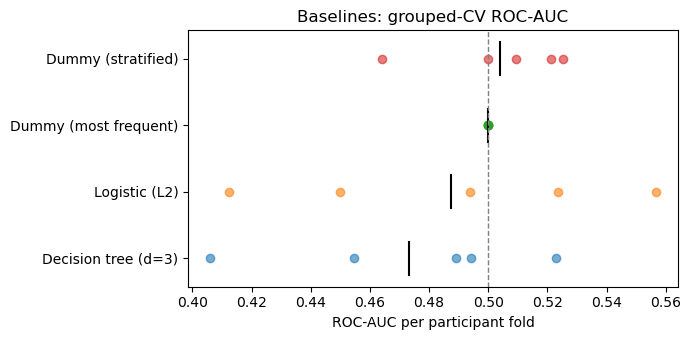

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
order = fold_scores.groupby("model", sort=False)["roc_auc"].mean().sort_values().index
for i, m in enumerate(order):
    v = fold_scores.loc[fold_scores.model == m, "roc_auc"]
    ax.scatter(v, [i] * len(v), alpha=.6); ax.plot([v.mean()] * 2, [i - .25, i + .25], color="k")
ax.axvline(.5, ls="--", c="grey", lw=1); ax.set_yticks(range(len(order)), order)
ax.set_xlabel("ROC-AUC per participant fold"); ax.set_title("Baselines: grouped-CV ROC-AUC")
plt.tight_layout(); plt.savefig(RESULTS / "baselines_auc_by_fold.png", dpi=150); plt.show()

### Diagnostic: grouped vs. row-level splitting
If the baselines are near AUC 0.5, check that this isn't a pipeline bug. Re-scoring the same models with an ordinary row-level `StratifiedKFold` (the same person appears in train and validation) shows how much apparent skill comes from memorizing individuals. This is **not** a valid estimate for our question; it's only a diagnostic.

In [8]:
from sklearn.model_selection import StratifiedKFold
row_folds = list(StratifiedKFold(5, shuffle=True, random_state=T.SEED).split(X, y))
diag = []
for name in ["Logistic (L2)", "Decision tree (d=3)"]:
    for split_name, f_ in [("participant-grouped (valid)", folds), ("row-level (leaky)", row_folds)]:
        f, _ = T.evaluate_cv(baselines[name], X, y, groups, f_, name)
        diag.append({"model": name, "split": split_name, "roc_auc": f.roc_auc.mean().round(3)})
pd.DataFrame(diag).pivot(index="model", columns="split", values="roc_auc")

split,participant-grouped (valid),row-level (leaky)
model,,
Decision tree (d=3),0.473,0.576
Logistic (L2),0.487,0.580


A clear gap (higher AUC with the row-level split) means the features identify *people* well but don't carry a sleep→mood relationship that transfers to new people. That's a substantive finding, and it motivates the person-centered features tried in the experiments notebook.

## 3. What the simple models learned

In [9]:
lr = T.make_logistic(C=1.0).fit(X, y)
names = lr.named_steps["impute"].get_feature_names_out(FEATURES)
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=names).sort_values(key=abs, ascending=False)
coefs.to_csv(RESULTS / "interpretability" / "baseline_logistic_coefficients.csv")
coefs.head(15).round(3).rename("standardized coef (log-odds per SD)").to_frame()

,standardized coef (log-odds per SD)
missingindicator_distance_perday_lag1,0.567
missingindicator_daily_full_sleep_breathing_rate,0.539
missingindicator_daily_nremhr,-0.245
missingindicator_daily_rmssd,-0.245
male,-0.235
bmi_num,0.192
missingindicator_daily_sleep_points_percentage,-0.187
daily_nremhr,0.139
daily_resting_hr_lag1,-0.138
daily_lightly_active_minutes_lag1,0.136


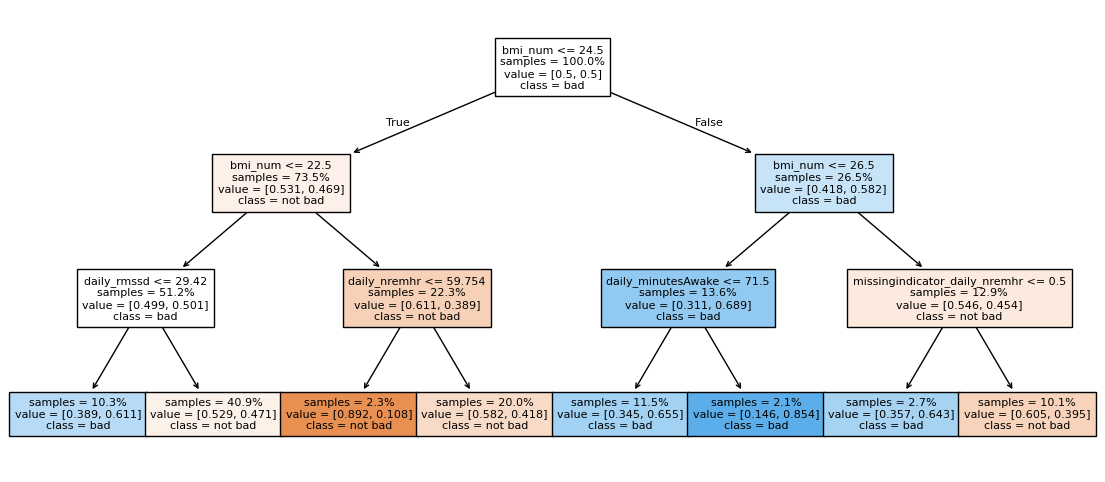

In [10]:
from sklearn.tree import plot_tree
tree = T.make_tree(max_depth=3, min_samples_leaf=50).fit(X, y)
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree.named_steps["model"], feature_names=list(tree.named_steps["impute"].get_feature_names_out(FEATURES)),
          class_names=["not bad", "bad"], filled=True, impurity=False, proportion=True, fontsize=8, ax=ax)
plt.savefig(RESULTS / "interpretability" / "baseline_tree.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Save results
These rows start `results/model_comparison.csv`; the experiments notebook appends to it.

In [11]:
summary = (fold_scores.drop(columns=["fold"]).groupby("model", sort=False).agg(["mean", "std"]))
summary.columns = [f"{a}_{b}" for a, b in summary.columns]
summary = summary.reset_index()
summary.insert(1, "family", ["dummy", "dummy", "linear", "tree"])
summary.insert(2, "hyperparameters", ["strategy=most_frequent", "strategy=stratified", "C=1.0, L2, balanced", "max_depth=3, min_samples_leaf=50, balanced"])
summary.insert(3, "notebook", "modeling_baselines")
summary.to_csv(RESULTS / "model_comparison.csv", index=False)
fold_scores.to_csv(RESULTS / "baselines_fold_scores.csv", index=False)
oof.to_csv(RESULTS / "baselines_oof_predictions.csv", index=False)
summary[["model", "accuracy_mean", "no_info_acc_mean", "hit_rate_mean", "false_alarm_mean", "roc_auc_mean", "roc_auc_std", "pr_auc_mean", "balanced_acc_mean"]].round(3)

,model,accuracy_mean,no_info_acc_mean,hit_rate_mean,false_alarm_mean,roc_auc_mean,roc_auc_std,pr_auc_mean,balanced_acc_mean
0,Dummy (most frequent),0.635,0.635,0.000,0.000,0.500,0.000,0.365,0.500
1,Dummy (stratified),0.542,0.635,0.362,0.354,0.504,0.024,0.367,0.504
2,Logistic (L2),0.474,0.635,0.552,0.568,0.487,0.057,0.367,0.492
3,Decision tree (d=3),0.459,0.635,0.445,0.526,0.473,0.045,0.361,0.460


## 5. Takeaways
- **No baseline beats chance with participant-grouped CV**: L2 logistic 0.487 ± 0.057, depth-3 tree 0.473 ± 0.045, vs. dummy 0.50.
- **The pipeline isn't broken**: the same models reach ~0.58 with a leaky row-level split. The features recognize *individuals*, but that doesn't transfer to new people.
- **What the logistic model leans on**: mostly missing-data indicators (how and when a person wears the device), plus gender, BMI and hour, rather than sleep or activity values. Missingness is person-specific, which is another sign the model is learning *who* rather than *when*.
- These numbers are the bar the experiments notebook has to clear.